***LAB 05***

**RANDOM FOREST CLASSIFIER**

Load dataset

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report

In [2]:
data = load_breast_cancer(as_frame=True).frame
print(data.head())

   mean radius  mean texture  mean perimeter  mean area  mean smoothness  \
0        17.99         10.38          122.80     1001.0          0.11840   
1        20.57         17.77          132.90     1326.0          0.08474   
2        19.69         21.25          130.00     1203.0          0.10960   
3        11.42         20.38           77.58      386.1          0.14250   
4        20.29         14.34          135.10     1297.0          0.10030   

   mean compactness  mean concavity  mean concave points  mean symmetry  \
0           0.27760          0.3001              0.14710         0.2419   
1           0.07864          0.0869              0.07017         0.1812   
2           0.15990          0.1974              0.12790         0.2069   
3           0.28390          0.2414              0.10520         0.2597   
4           0.13280          0.1980              0.10430         0.1809   

   mean fractal dimension  ...  worst texture  worst perimeter  worst area  \
0             

Load dataset from CSV (alternative)

In [3]:
#save the dataset to csv
data.to_csv('breast_cancer.csv', index=False)

#load the dataset from csv (for your own file just change the file name/path)
data = pd.read_csv('breast_cancer.csv')
print(data.shape)

(569, 31)


Data preprocessing

In [4]:
#handle missing values
print(data.isnull().sum().sum())

#if a csv has missing values, fill numeric columns with median
data = data.fillna(data.median(numeric_only=True))

0


In [5]:
#encode categorical data (this dataset is fully numeric so nothing changes, but this works for any csv)
cat_cols = data.select_dtypes(include='object').columns
print('Categorical columns:', list(cat_cols))
data = pd.get_dummies(data, columns=cat_cols, drop_first=True)

Categorical columns: []


In [6]:
#split the dataset into training and testing sets
X = data.drop(columns='target')
y = data['target']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

Train Random Forest Classifier

In [7]:
rf = RandomForestClassifier(n_estimators=100, random_state=42)
rf.fit(X_train, y_train)

#predict on test set
rf_pred = rf.predict(X_test)

Evaluate performance

In [8]:
print('Accuracy  =', accuracy_score(y_test, rf_pred))
print('Precision =', precision_score(y_test, rf_pred))
print('Recall    =', recall_score(y_test, rf_pred))
print('F1-score  =', f1_score(y_test, rf_pred))
print()
print(classification_report(y_test, rf_pred, target_names=['Malignant','Benign']))

Accuracy  = 0.956140350877193
Precision = 0.958904109589041
Recall    = 0.9722222222222222
F1-score  = 0.9655172413793104

              precision    recall  f1-score   support

   Malignant       0.95      0.93      0.94        42
      Benign       0.96      0.97      0.97        72

    accuracy                           0.96       114
   macro avg       0.96      0.95      0.95       114
weighted avg       0.96      0.96      0.96       114



Visualize the Confusion Matrix

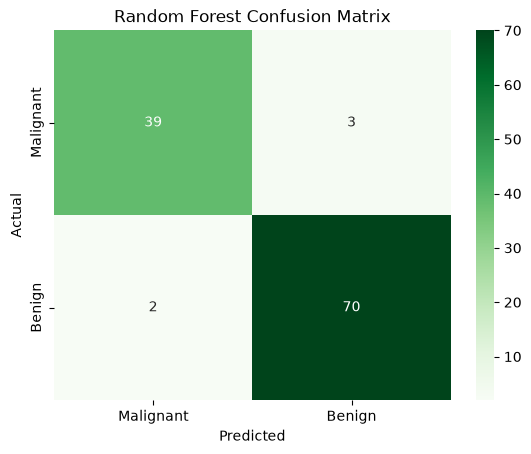

In [9]:
cm = confusion_matrix(y_test, rf_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Greens', xticklabels=['Malignant','Benign'], yticklabels=['Malignant','Benign'])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Random Forest Confusion Matrix')
plt.show()

Feature importance (which features the forest used the most)

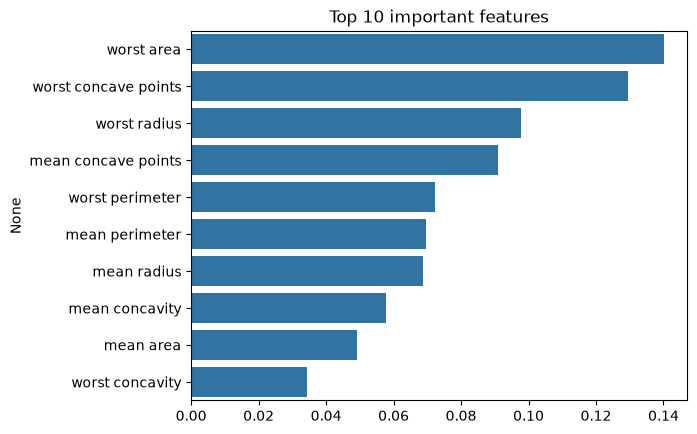

In [10]:
imp = pd.Series(rf.feature_importances_, index=X.columns).sort_values(ascending=False).head(10)
sns.barplot(x=imp.values, y=imp.index)
plt.title('Top 10 important features')
plt.show()

Compare with a Single Decision Tree

In [11]:
dt = DecisionTreeClassifier(random_state=42)
dt.fit(X_train, y_train)
dt_pred = dt.predict(X_test)

def metrics(y_true, y_pred):
    return [accuracy_score(y_true, y_pred), precision_score(y_true, y_pred), recall_score(y_true, y_pred), f1_score(y_true, y_pred)]

results = pd.DataFrame([metrics(y_test, dt_pred), metrics(y_test, rf_pred)],
                       columns=['Accuracy', 'Precision', 'Recall', 'F1-score'],
                       index=['Decision Tree', 'Random Forest'])
print(results.round(3))

               Accuracy  Precision  Recall  F1-score
Decision Tree     0.912      0.956   0.903     0.929
Random Forest     0.956      0.959   0.972     0.966


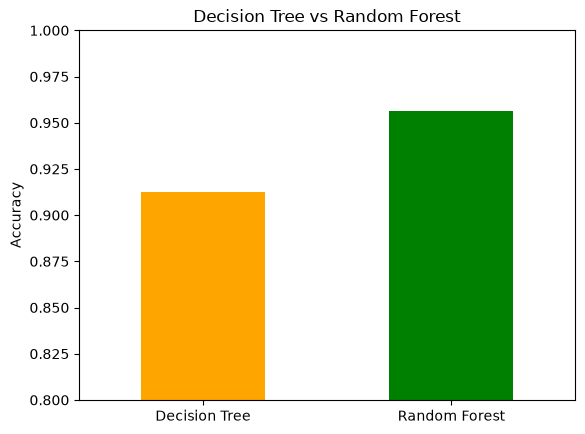

In [12]:
results['Accuracy'].plot(kind='bar', color=['orange','green'], ylim=(0.8, 1.0))
plt.ylabel('Accuracy')
plt.title('Decision Tree vs Random Forest')
plt.xticks(rotation=0)
plt.show()

Random Forest performs better (or at least equal) than a single decision tree on every metric.

A single tree is trained on the whole training data and can overfit it. A random forest trains many trees on different bootstrap samples (bagging) and uses random subsets of features at each split, then takes the majority vote. Errors of individual trees cancel each other out, so the variance is lower and the model generalizes better.